In [ ]:
import torch
print(torch.cuda.is_available())

False


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
!cp -r "/content/drive/MyDrive/MRI images" /content/MRI_images

# Import Libraries and Tools

In [5]:
import os
import numpy as np
import random
from PIL import Image, ImageEnhance
from tensorflow.keras.preprocessing.image import load_img
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Flatten, Dropout, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.applications import VGG16
from sklearn.utils import shuffle

# Load Dataset

In [6]:
# Directories for training and testing data
train_dir = '/content/MRI_images/Training/'
test_dir = '/content/MRI_images/Testing/'

# Load and shuffle the train data
train_paths = []
train_labels = []
for label in os.listdir(train_dir):
    for image in os.listdir(os.path.join(train_dir, label)):
      train_paths.append(os.path.join(train_dir, label, image))
      train_labels.append(label)

train_paths, train_labels = shuffle(train_paths, train_labels)


# Load and shuffle the test data
test_paths = []
test_labels = []
for label in os.listdir(test_dir):
    for image in os.listdir(os.path.join(test_dir, label)):
      test_paths.append(os.path.join(test_dir, label, image))
      test_labels.append(label)

test_paths, test_labels = shuffle(test_paths, test_labels)


# Data Visualizaation

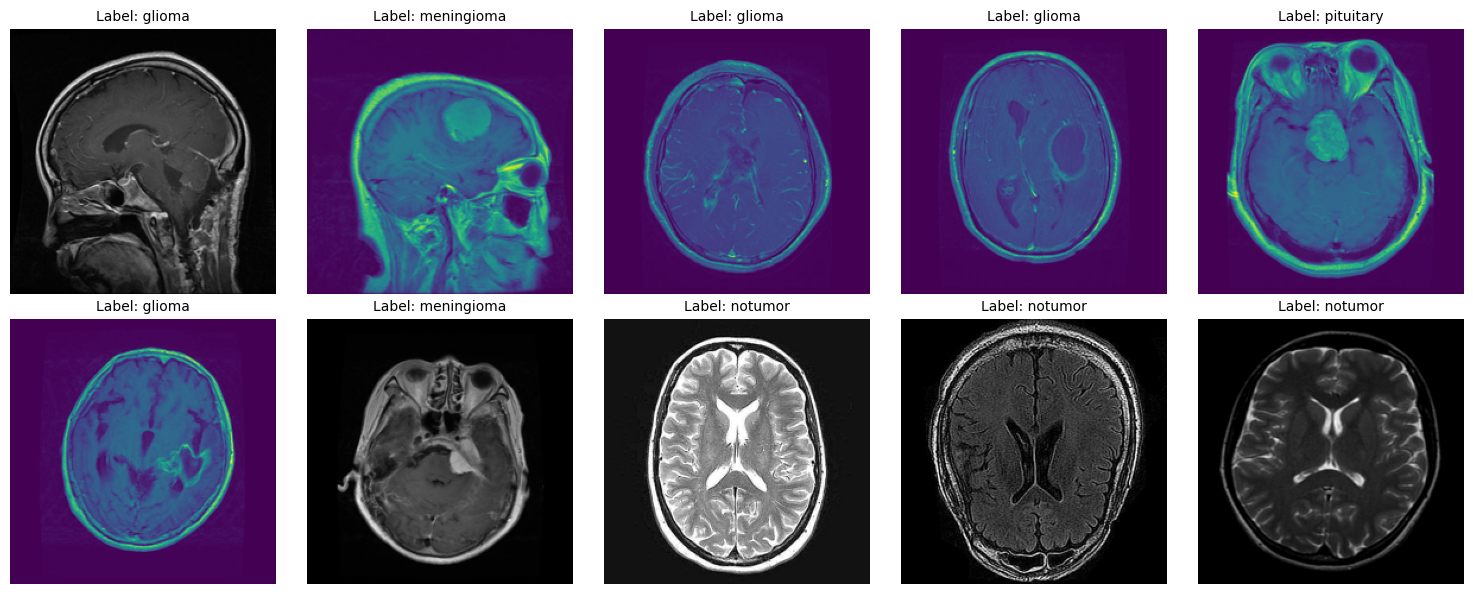

In [ ]:
import random
import matplotlib.pyplot as plt

# select random indcies for 10 images
random_indcies = random.sample(range(len(train_paths)),10)

# Create a figure display images in 2 rows
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.ravel()

# loop through the random indcies and display images
for i, idx in enumerate(random_indcies):
  # load image
  img_path = train_paths[idx]
  img = Image.open(img_path)
  img = img.resize((224, 224))

  # display images
  axes[i].imshow(img)
  axes[i].axis('off')
  # display class label
  axes[i].set_title(f"Label: {train_labels[idx]}", fontsize=10)

plt.tight_layout()
plt.show()


# Image Preprocessing

In [ ]:
# Image Augmentation function
def augment_image(image):
    image = Image.fromarray(np.uint8(image))
    image = ImageEnhance.Brightness(image).enhance(random.uniform(0.8, 1.2))  # Random brightness
    image = ImageEnhance.Contrast(image).enhance(random.uniform(0.8, 1.2))  # Random contrast
    image = np.array(image) / 255.0  # Normalize pixel values to [0, 1]
    return image

# Load images and apply augmentation
def open_images(paths):
    images = []
    for path in paths:
        image = load_img(path, target_size=(IMAGE_SIZE, IMAGE_SIZE))
        image = augment_image(image)
        images.append(image)
    return np.array(images)

# Encoding labels (convert label names to integers)
def encode_label(labels):
    unique_labels = os.listdir(train_dir)  # Ensure unique labels are determined
    encoded = [unique_labels.index(label) for label in labels]
    return np.array(encoded)

# Data generator for batching
def datagen(paths, labels, batch_size=12, epochs=1):
    for _ in range(epochs):
        for i in range(0, len(paths), batch_size):
            batch_paths = paths[i:i + batch_size]
            batch_images = open_images(batch_paths)
            batch_labels = labels[i:i + batch_size]
            batch_labels = encode_label(batch_labels)
            yield batch_images, batch_labels

In [ ]:
import time
t = time.time()
x, y = next(datagen(train_paths, train_labels, batch_size=20))
print(round(time.time() - t, 2), "detik untuk 1 batch")
print(x.shape, y)

0.04 detik untuk 1 batch
(20, 128, 128, 3) [1 0 2 3 2 3 3 1 0 1 3 1 0 2 1 1 2 0 1 3]


In [ ]:
# Model architecture
IMAGE_SIZE = 128  # Image size (adjust based on your requirements)
base_model = VGG16(input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3), include_top=False, weights='imagenet')

# Freeze all layers of the VGG16 base model
for layer in base_model.layers:
    layer.trainable = False

# Set the last few layers of the VGG16 base model to be trainable
base_model.layers[-2].trainable = True
base_model.layers[-3].trainable = True
base_model.layers[-4].trainable = True

# Build the final model
model = Sequential()
model.add(Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3)))  # Input layer
model.add(base_model)  # Add VGG16 base model
model.add(Flatten())  # Flatten the output of the base model
model.add(Dropout(0.3))  # Dropout layer for regularization
model.add(Dense(128, activation='relu'))  # Dense layer with ReLU activation
model.add(Dropout(0.2))  # Dropout layer for regularization
model.add(Dense(len(os.listdir(train_dir)), activation='softmax'))  # Output layer with softmax activation

# Compile the model
model.compile(optimizer=Adam(learning_rate=0.0001),
              loss='sparse_categorical_crossentropy',
              metrics=['sparse_categorical_accuracy'])

# Parameters
batch_size = 20
steps = int(len(train_paths) / batch_size)  # Steps per epoch
epochs = 5

# Train the model
history = model.fit(datagen(train_paths, train_labels, batch_size=batch_size, epochs=epochs),
                    epochs=epochs, steps_per_epoch=steps)

Epoch 1/5
280/280 ━━━━━━━━━━━━━━━━━━━━ 31s 75ms/step - loss: 0.4768 - sparse_categorical_accuracy: 0.8173
Epoch 2/5
280/280 ━━━━━━━━━━━━━━━━━━━━ 22s 80ms/step - loss: 0.2291 - sparse_categorical_accuracy: 0.9141
Epoch 3/5
280/280 ━━━━━━━━━━━━━━━━━━━━ 21s 76ms/step - loss: 0.1776 - sparse_categorical_accuracy: 0.9355
Epoch 4/5
280/280 ━━━━━━━━━━━━━━━━━━━━ 22s 79ms/step - loss: 0.1227 - sparse_categorical_accuracy: 0.9546
Epoch 5/5
280/280 ━━━━━━━━━━━━━━━━━━━━ 21s 76ms/step - loss: 0.0980 - sparse_categorical_accuracy: 0.9652


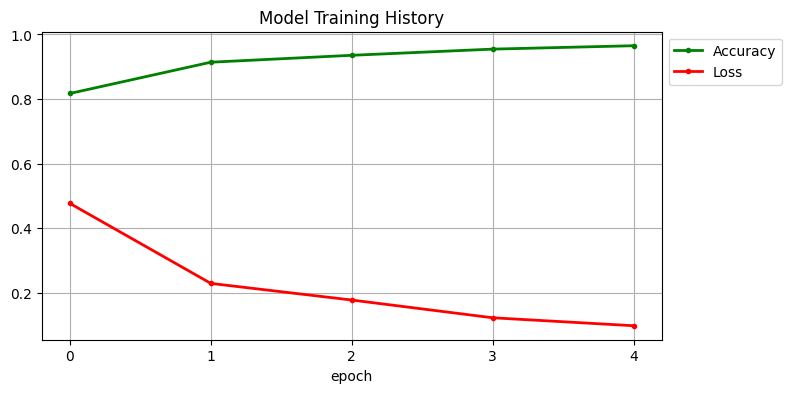

In [ ]:
plt.figure(figsize=(8,4))
plt.grid(True)
plt.plot(history.history['sparse_categorical_accuracy'], '.g-', linewidth=2)
plt.plot(history.history['loss'], '.r-', linewidth=2)
plt.title('Model Training History')
plt.xlabel('epoch')
plt.xticks([x for x in range(epochs)])
plt.legend(['Accuracy', 'Loss'], loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
import seaborn as sns
from sklearn.preprocessing import label_binarize
from tensorflow.keras.models import load_model
import numpy as np

# 1. Prediction on test data
test_images = open_images(test_paths)  # Load and augment test images
test_labels_encoded = encode_label(test_labels)  # Encode the test labels

# Predict using the trained model
test_predictions = model.predict(test_images)

# 2. Classification Report
print("Classification Report:")
print(classification_report(test_labels_encoded, np.argmax(test_predictions, axis=1)))

50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 42ms/step
Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.87      0.88       400
           1       0.90      0.99      0.94       400
           2       0.94      0.80      0.86       400
           3       0.93      1.00      0.96       400

    accuracy                           0.91      1600
   macro avg       0.91      0.91      0.91      1600
weighted avg       0.91      0.91      0.91      1600



Confusion Matrix:
[[348  31  19   2]
 [  3 395   2   0]
 [ 41  12 319  28]
 [  0   0   1 399]]


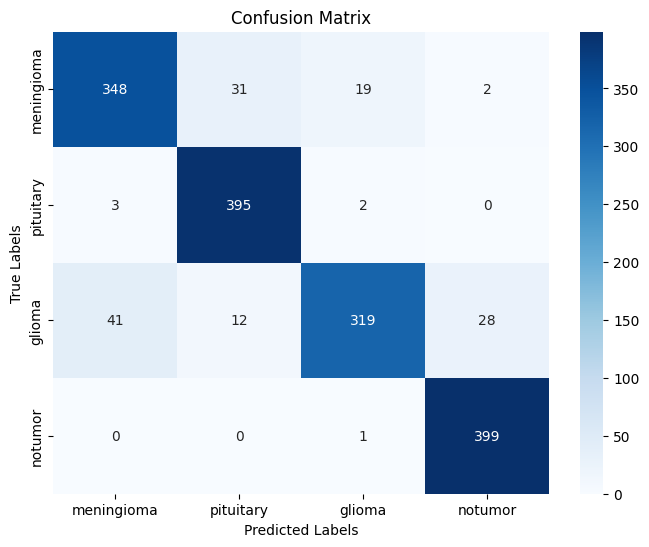

In [ ]:
# 3. Confusion Matrix
conf_matrix = confusion_matrix(test_labels_encoded, np.argmax(test_predictions, axis=1))
print("Confusion Matrix:")
print(conf_matrix)

# Plot the Confusion Matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=os.listdir(train_dir), yticklabels=os.listdir(train_dir))
plt.title("Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()

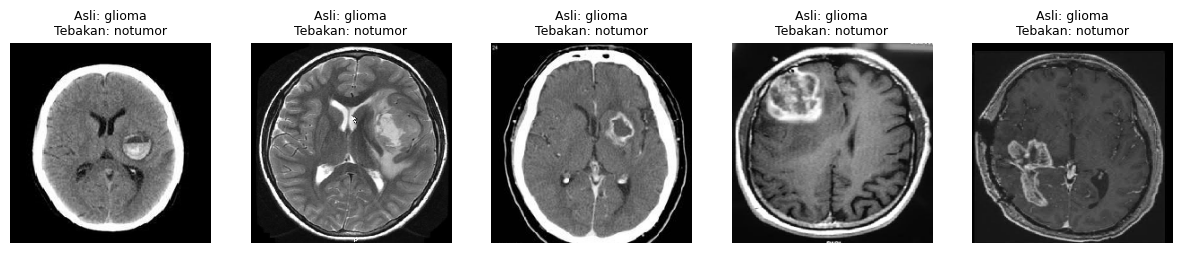

In [ ]:
pred = np.argmax(test_predictions, axis=1)
kelas = os.listdir(train_dir)
salah = np.where((test_labels_encoded == 2) & (pred == 3))[0]

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for ax, i in zip(axes, salah[:5]):
    ax.imshow(load_img(test_paths[i], target_size=(224, 224)))
    ax.set_title(f"Asli: {kelas[test_labels_encoded[i]]}\nTebakan: {kelas[pred[i]]}", fontsize=9)
    ax.axis('off')
plt.show()

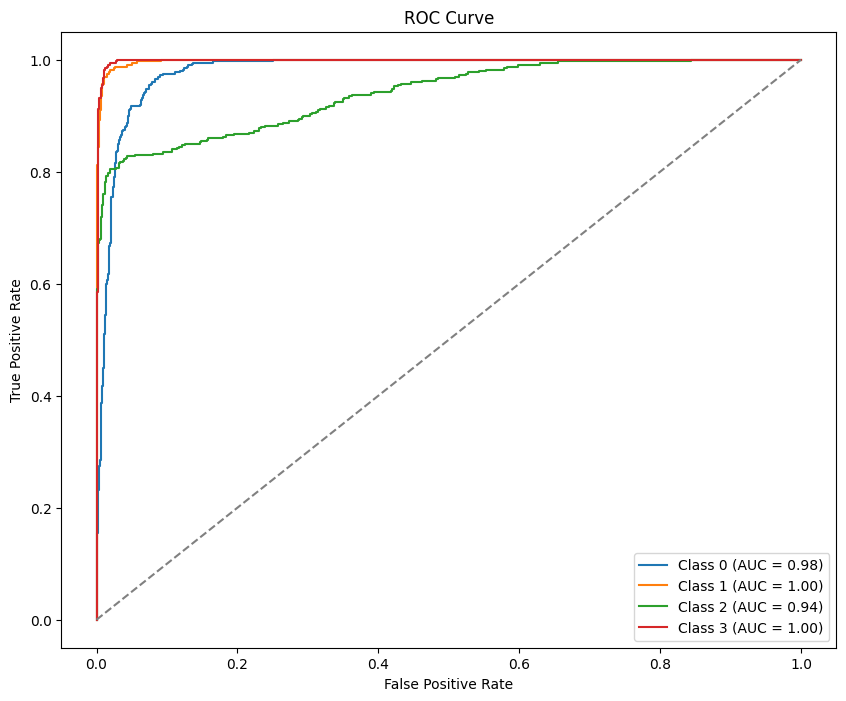

In [ ]:
# 4. ROC Curve and AUC
# Binarize the test labels and predictions for multi-class ROC
test_labels_bin = label_binarize(test_labels_encoded, classes=np.arange(len(os.listdir(train_dir))))
test_predictions_bin = test_predictions  # The predicted probabilities for each class

# Compute ROC curve and ROC AUC for each class
fpr, tpr, roc_auc = {}, {}, {}
for i in range(len(os.listdir(train_dir))):
    fpr[i], tpr[i], _ = roc_curve(test_labels_bin[:, i], test_predictions_bin[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot ROC curve
plt.figure(figsize=(10, 8))
for i in range(len(os.listdir(train_dir))):
    plt.plot(fpr[i], tpr[i], label=f'Class {i} (AUC = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], linestyle='--', color='gray')  # Diagonal line
plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.show()

In [ ]:
model.save('/content/drive/MyDrive/brain_tumor_vgg16.keras')

In [ ]:
import json
with open('/content/drive/MyDrive/class_labels.json', 'w') as f:
    json.dump(os.listdir(train_dir), f)

# MRI Tumor Detection System

In [7]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import load_img, img_to_array

model = load_model('/content/drive/MyDrive/brain_tumor_vgg16.keras')


class_labels = ['meningioma', 'pituitary', 'glioma', 'notumor']

def detect_and_display(img_path, model, image_size=128):
    try:
        img = load_img(img_path, target_size=(image_size, image_size))
        img_array = img_to_array(img) / 255.0
        img_array = np.expand_dims(img_array, axis=0)

        predictions = model.predict(img_array, verbose=0)
        predicted_class_index = np.argmax(predictions, axis=1)[0]
        confidence_score = np.max(predictions, axis=1)[0]

        if class_labels[predicted_class_index] == 'notumor':
            result = "No Tumor"
        else:
            result = f"Tumor: {class_labels[predicted_class_index]}"

        plt.imshow(load_img(img_path))
        plt.axis('off')
        plt.title(f"{result} (Confidence: {confidence_score * 100:.2f}%)")
        plt.show()

    except Exception as e:
        print("Error processing the image:", str(e))

Folder asli: pituitary


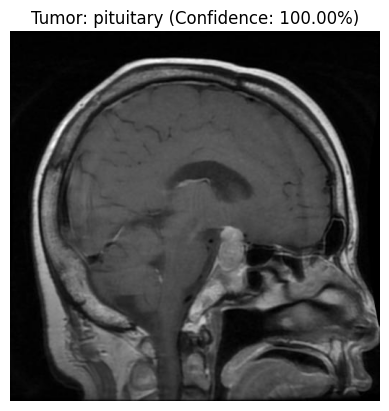

Folder asli: notumor


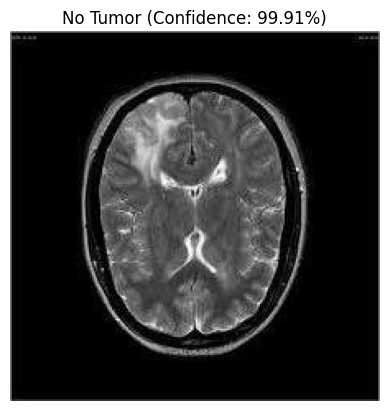

Folder asli: meningioma


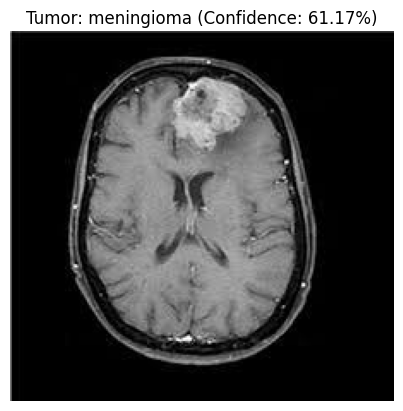

Folder asli: glioma


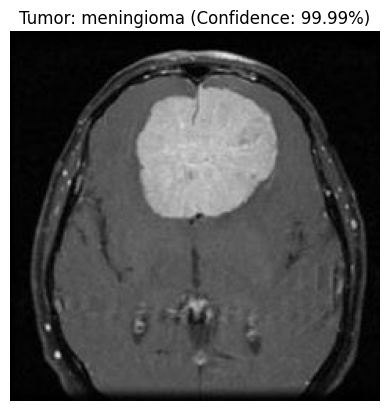

In [8]:
base = '/content/drive/MyDrive/MRI images/Testing'
for kelas in os.listdir(base):
    f = random.choice(os.listdir(os.path.join(base, kelas)))
    print("Folder asli:", kelas)
    detect_and_display(os.path.join(base, kelas, f), model)
